# Diagnóstico de pneumonia no raio-X — Parte B (EXTRA)

Este notebook classifica radiografias de tórax em **NORMAL** ou **PNEUMONIA**, com redes neurais convolucionais (CNN), o tipo de rede feito para imagens.

**A base:** Chest X-Ray Images (Pneumonia), do Kaggle. São 5.856 radiografias de crianças de 1 a 5 anos, de um hospital de Guangzhou, na China (Kermany et al., 2018). Médicos rotularam cada imagem.

**A métrica principal é o recall de PNEUMONIA:** dos doentes, quantos o modelo encontra. Deixar passar uma pneumonia é o erro mais grave.

O modelo é um apoio à triagem: a decisão final é sempre do médico.

| Etapa | O que faz |
| --- | --- |
| B0 a B2 | prepara o Colab, baixa a base e carrega as imagens |
| B3 | explora as imagens |
| B4 | separa treino, validação e teste |
| B5 a B8 | treina 3 modelos: 2 CNNs e um modelo sem rede neural |
| B9 | escolhe o modelo na validação |
| B10 | mede o modelo escolhido no teste |
| B11 | mostra onde o modelo olha |
| B12 e B13 | textos do relatório, requirements.txt e figuras |

**Como rodar:** menu Ambiente de execução → Alterar o tipo de ambiente de execução → **T4 GPU** → Salvar. Depois, Ambiente de execução → Executar tudo. Com GPU, tudo leva de 15 a 30 minutos.

## B0. Preparar e conferir a GPU

Esta célula carrega as bibliotecas e confere se a GPU está ligada.

**Por que usar GPU?** A GPU (a placa de vídeo) faz milhares de contas ao mesmo tempo. Por isso, o treino da CNN fica muitas vezes mais rápido que no processador comum (CPU). O Colab oferece uma GPU **T4** de graça, com limite de uso.

**Sem GPU, o notebook também roda**, só que mais devagar. Se a saída mostrar `GPU: DESLIGADA`, ligue a GPU (veja "Como rodar", acima) e use Executar tudo de novo: trocar o ambiente reinicia a sessão.

In [1]:
# "import" traz uma biblioteca pronta. "as" dá um apelido curto. "from X import a, b" traz só as partes a e b.
import os                                                      # os: lida com pastas e arquivos
import sys                                                     # sys: informações do Python; aqui, serve para saber se estamos no Colab
# cv2 é o OpenCV, uma biblioteca de visão computacional: lê, converte e redimensiona imagens.
import cv2                                                     # OpenCV: ler e tratar imagens
import numpy as np                                             # NumPy: cada imagem vira uma matriz de números, e o NumPy faz as contas com ela
import pandas as pd                                            # pandas: tabelas de resultados (igual à Parte A)
import matplotlib.pyplot as plt                                # Matplotlib: gráficos e exibição de imagens
import tensorflow as tf                                        # TensorFlow: a biblioteca que monta e treina as redes neurais
# Keras é a parte do TensorFlow para montar redes. layers são as camadas; models junta as camadas num modelo.
from tensorflow.keras import layers, models                    # camadas e modelo
os.makedirs('figuras', exist_ok=True)                          # pasta dos gráficos; exist_ok=True evita erro se ela já existir
# list_physical_devices('GPU') lista as GPUs que o TensorFlow encontrou. Lista vazia = sem GPU.
gpus = tf.config.list_physical_devices('GPU')                  # GPUs disponíveis
print('TensorFlow:', tf.__version__)                           # __version__ guarda a versão instalada
# "A if condição else B": mostra a lista de GPUs se ela não estiver vazia; se estiver, mostra o aviso.
print('GPU:', gpus if gpus else 'DESLIGADA (veja a célula de texto acima)')  # lista vazia = GPU desligada

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## B1. Baixar a base

A biblioteca `kagglehub`, do próprio Kaggle, baixa a base (cerca de 2,5 GB) direto para o Colab. Leva de 1 a 2 minutos.

A base já vem separada em 3 pastas, cada uma com uma subpasta por classe:

| Pasta | NORMAL | PNEUMONIA | Total |
| --- | --- | --- | --- |
| train | 1.341 | 3.875 | 5.216 |
| val | 8 | 8 | 16 |
| test | 234 | 390 | 624 |

**Por que não usamos a pasta `val`?** Ela tem só 16 imagens. Com 8 imagens por classe, um único erro muda o recall em 12,5 pontos. Uma medida tão instável não serve para escolher um modelo. A validação sai de dentro do treino, no passo B4.

In [2]:
# "!" no começo da linha roda um comando do terminal. pip install instala uma biblioteca; -q mostra menos mensagens.
!pip install -q kagglehub                                      # instala o baixador do Kaggle (se já existir, não faz nada)
import kagglehub                                               # biblioteca oficial do Kaggle
# dataset_download baixa a base pelo nome "dono/base" e devolve a pasta onde ela foi salva.
path = kagglehub.dataset_download('paultimothymooney/chest-xray-pneumonia')  # baixa cerca de 2,5 GB
# A base vem com pastas dentro de pastas. O código abaixo procura a pasta que tem train/ e test/ dentro.
BASE = None                                                    # None quer dizer "ainda não achou"
# os.walk percorre todas as pastas a partir de path. A cada passo, devolve a pasta atual (raiz),
# as subpastas dela (pastas) e os arquivos dela (arquivos).
for raiz, pastas, arquivos in os.walk(path):                   # percorre as pastas baixadas, de cima para baixo
    # __MACOSX é uma pasta de lixo que o Mac cria ao compactar. Ela repete os nomes e confundiria a busca.
    if '__MACOSX' in raiz:                                     # é a pasta de lixo?
        continue                                               # continue pula direto para a próxima pasta
    if 'train' in pastas and 'test' in pastas:                 # esta pasta tem train/ e test/ dentro?
        BASE = raiz                                            # guarda o caminho
        break                                                  # break encerra o laço: já achou
print(BASE)                                                    # caminho da base
# Confere a base: conta as imagens de cada pasta e de cada classe.
for parte in ['train', 'val', 'test']:                         # cada pasta da base
    for classe in ['NORMAL', 'PNEUMONIA']:                     # cada classe
        # os.path.join junta pedaços de um caminho com a barra certa. os.listdir lista os arquivos da pasta.
        nomes = os.listdir(os.path.join(BASE, parte, classe))  # nomes dos arquivos
        # endswith('.jpeg') fica só com as imagens, sem contar arquivos ocultos. len conta os itens da lista.
        n = len([a for a in nomes if a.endswith('.jpeg')])     # número de imagens
        print(parte, classe, n)                                # esperado: 1341, 3875, 8, 8, 234, 390

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
/kaggle/input/chest-xray-pneumonia/chest_xray
train NORMAL 1341
train PNEUMONIA 3875
val NORMAL 8
val PNEUMONIA 8
test NORMAL 234
test PNEUMONIA 390


## B2. Carregar as imagens

A CNN só aceita imagens do mesmo tamanho e com o mesmo número de canais. Por isso, cada radiografia passa por 3 passos:

1. **Ler** o arquivo com o OpenCV.
2. **Passar para tons de cinza** (1 canal).
3. **Reduzir para 128 × 128 pixels.**

**Por que tons de cinza?** Num raio-X, os 3 canais de cor são iguais ou quase iguais. Com 1 canal, a imagem fica 3 vezes menor, e quase nada se perde.

**Por que 128 × 128?** É um meio-termo. Maior, o treino fica lento e pesado (256 × 256 tem 4 vezes mais pixels). Menor, somem detalhes do pulmão, como as manchas da pneumonia.

**Por que NORMAL = 0 e PNEUMONIA = 1?** Assim, o recall, a precisão e o F1 medem a classe doente, como Maligno = 1 na Parte A.

**O paciente de cada imagem.** O nome do arquivo traz o código do paciente: `person12_bacteria_3.jpeg` é do paciente `person12_bacteria`. O tipo (bactéria ou vírus) entra no código, porque o número sozinho se repete entre os dois tipos. O código serve para separar a validação por paciente (B4).

**O teste fica guardado.** As 624 imagens de teste são carregadas agora, mas só são usadas no fim (B10).

Esta etapa leva alguns minutos.

In [3]:
import re                                                      # re: expressões regulares, para achar um padrão dentro de um texto
# Lado da imagem depois do redimensionamento. 128 x 128 guarda detalhe suficiente e cabe na memória do Colab.
TAMANHO = 128                                                  # imagens de 128 x 128 pixels
# A posição na lista vira o rótulo: 0 = NORMAL, 1 = PNEUMONIA. A doença fica como classe 1, como na Parte A.
CLASSES = ['NORMAL', 'PNEUMONIA']                              # rótulo 0 e rótulo 1

# O nome de cada arquivo traz o código do paciente. Ele serve para separar a validação por paciente (passo B4).
# PNEUMONIA: "person12_bacteria_3.jpeg" vira "person12_bacteria". O tipo entra no código porque o número
# sozinho se repete entre bactéria e vírus. NORMAL: "IM-0115-0001.jpeg" vira "IM-0115".
def paciente(nome):                                            # recebe o nome do arquivo
    # re.match procura o padrão no começo do nome; group(1) devolve o pedaço entre parênteses: o código.
    return re.match(r'(person\d+_[a-z]+|.*?IM-\d+)', nome).group(1)  # código do paciente

# def cria uma função: um bloco de código com nome, para usar mais de uma vez (aqui, no treino e no teste).
def carregar_pasta(pasta):                                     # recebe o caminho de train/ ou test/
    imagens, rotulos, pacientes = [], [], []                   # três listas vazias: imagens, rótulos e pacientes
    # enumerate dá a posição (0 ou 1) e o nome de cada classe.
    for rotulo, classe in enumerate(CLASSES):                  # 0 = NORMAL, 1 = PNEUMONIA
        dir_classe = os.path.join(pasta, classe)               # caminho da subpasta da classe
        # sorted ordena os nomes, para as imagens entrarem sempre na mesma ordem.
        for nome in sorted(os.listdir(dir_classe)):            # cada arquivo da subpasta
            # imread lê a imagem em cores, no formato BGR do OpenCV. Se o arquivo não for imagem, devolve None.
            img = cv2.imread(os.path.join(dir_classe, nome))   # lê a imagem
            if img is None:                                    # arquivo oculto ou estragado?
                continue                                       # pula o arquivo
            # cvtColor converte as cores. COLOR_BGR2GRAY passa para tons de cinza: 1 canal em vez de 3.
            # O raio-X já é cinza, então não perde informação, e a imagem fica 3 vezes menor.
            img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)        # cinza: 1 canal
            # resize muda o tamanho: a CNN exige todas as imagens do mesmo tamanho.
            # INTER_AREA é o modo indicado para diminuir imagens: perde menos detalhe.
            img = cv2.resize(img, (TAMANHO, TAMANHO), interpolation=cv2.INTER_AREA)  # 128 x 128
            imagens.append(img)                                # append acrescenta a imagem no fim da lista
            rotulos.append(rotulo)                             # guarda o rótulo (0 ou 1) na mesma posição
            pacientes.append(paciente(nome))                   # guarda o paciente, também na mesma posição
    # np.array transforma as listas em matrizes do NumPy, o formato que o TensorFlow e o scikit-learn usam.
    return np.array(imagens), np.array(rotulos), np.array(pacientes)  # return devolve o resultado da função

X_treino_total, y_treino_total, pac_treino_total = carregar_pasta(os.path.join(BASE, 'train'))  # 5.216 imagens
# O teste fica guardado como um "cofre": só é usado no fim, depois de todas as escolhas.
# "bruto" = ainda com pixels de 0 a 255; a versão pronta para a rede (X_teste) é criada no passo B4.
# Os pacientes do teste servem só para conferir, no B4, que o teste não tem pacientes do treino.
X_teste_bruto, y_teste, pac_teste = carregar_pasta(os.path.join(BASE, 'test'))  # 624 imagens de teste
print(X_treino_total.shape, X_teste_bruto.shape)               # esperado: (5216, 128, 128) (624, 128, 128)
# set elimina as repetições; len conta quantos pacientes diferentes há no treino.
print('Pacientes no treino:', len(set(pac_treino_total)))      # esperado: 3654

(5216, 128, 128) (624, 128, 128)
Pacientes no treino: 3654


## B3. Explorar

Em imagens, explorar é olhar as próprias imagens e alguns números simples. As 4 células abaixo respondem a 4 perguntas:

1. **Quantas imagens há de cada classe, e de que tamanho?**
2. **Como é um raio-X de cada classe?** São 9 exemplos.
3. **O que muda, em média, entre as classes?** É o "raio-X médio" de cada classe e a diferença entre eles.
4. **As classes diferem no brilho geral?**

**O que observar:**

- **Classes desequilibradas:** 74% do treino é PNEUMONIA. Um modelo que chamasse todos de doentes já acertaria 74%. Por isso, a acurácia sozinha engana.
- **O teste é diferente:** ele tem 62,5% de PNEUMONIA, menos que o treino.
- **Onde fica a diferença:** na pneumonia, o pulmão ganha áreas mais brancas. Na imagem média, isso deve aparecer no centro. Se a diferença forte estiver nas bordas, o modelo pode aprender pistas que não são a doença, como marcas do aparelho.

In [4]:
# bincount conta quantas vezes aparece cada número: quantos 0 (NORMAL) e quantos 1 (PNEUMONIA).
print('Treino:', np.bincount(y_treino_total))                  # esperado: [1341 3875] = [NORMAL, PNEUMONIA]
print('Teste:', np.bincount(y_teste))                          # esperado: [234 390]
# Como os rótulos são 0 e 1, a média é a proporção de 1, ou seja, de PNEUMONIA.
print('PNEUMONIA no treino:', round(y_treino_total.mean(), 3))  # esperado: 0.743 = 74%
print('PNEUMONIA no teste:', round(y_teste.mean(), 3))         # esperado: 0.625 = 62,5%: o teste tem mais NORMAL
# Agora olha o tamanho original de algumas imagens, antes do redimensionamento.
pasta = os.path.join(BASE, 'train', 'NORMAL')                  # uma pasta da base
for nome in sorted(os.listdir(pasta))[:5]:                     # [:5] pega os 5 primeiros arquivos
    img = cv2.imread(os.path.join(pasta, nome))                # lê a imagem original
    if img is not None:                                        # é imagem?
        print(nome, img.shape)                                 # (altura, largura, 3 canais de cor): os tamanhos variam

Treino: [1341 3875]
Teste: [234 390]
PNEUMONIA no treino: 0.743
PNEUMONIA no teste: 0.625
IM-0115-0001.jpeg (1858, 2090, 3)
IM-0117-0001.jpeg (1152, 1422, 3)
IM-0119-0001.jpeg (1434, 1810, 3)
IM-0122-0001.jpeg (1279, 1618, 3)
IM-0125-0001.jpeg (1125, 1600, 3)


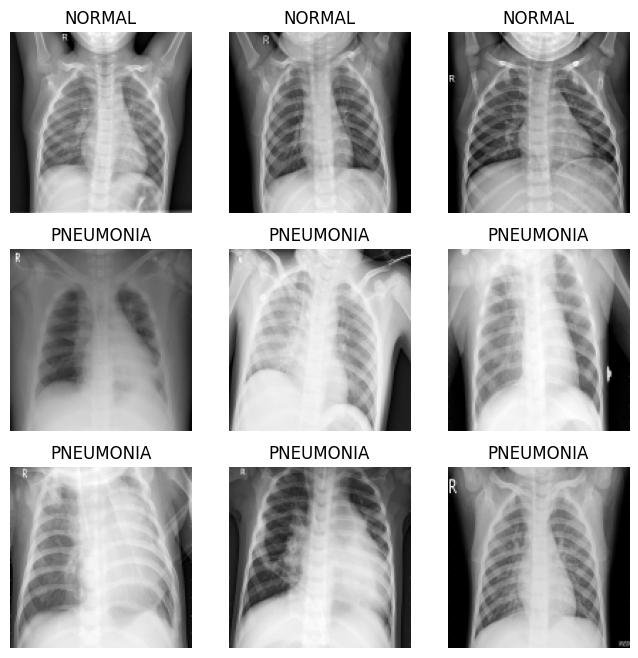

In [5]:
plt.figure(figsize=(8, 8))                                     # nova figura, com 8 x 8 polegadas
for i in range(9):                                             # range(9) gera 0, 1, ..., 8: são 9 exemplos
    # As imagens estão em ordem: primeiro as NORMAL, depois as PNEUMONIA.
    # Pular de 500 em 500 (0, 500, ..., 4000) pega exemplos das duas classes.
    j = i * 500                                                # posição da imagem
    plt.subplot(3, 3, i + 1)                                   # subplot(3, 3, k): o quadro k de uma grade 3 x 3 (k começa em 1)
    plt.imshow(X_treino_total[j], cmap='gray')                 # imshow desenha a matriz como imagem; cmap='gray' usa tons de cinza
    plt.title(CLASSES[y_treino_total[j]])                      # o rótulo (0 ou 1) vira o nome da classe no título
    plt.axis('off')                                            # esconde os eixos: numa foto, eles não ajudam
plt.savefig('figuras/pneumonia_exemplos.png')                  # salva o gráfico
plt.show()                                                     # mostra o gráfico

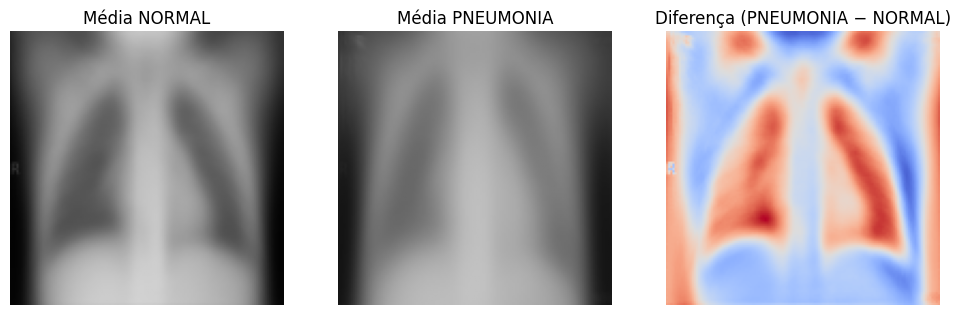

In [6]:
# Média de todas as imagens de uma classe, pixel a pixel: o "raio-X médio" daquela classe.
# y_treino_total == 0 marca as NORMAL; X_treino_total[...] filtra só elas; mean(axis=0) faz a média entre as imagens.
media_normal = X_treino_total[y_treino_total == 0].mean(axis=0)  # raio-X médio dos NORMAL
media_pneumonia = X_treino_total[y_treino_total == 1].mean(axis=0)  # raio-X médio dos PNEUMONIA
# A diferença mostra onde os doentes são, em média, mais claros (valor positivo) ou mais escuros (negativo).
diferenca = media_pneumonia - media_normal                     # PNEUMONIA menos NORMAL, pixel a pixel
# O maior valor da diferença, sem sinal. Ele deixa a escala de cores simétrica em volta do zero.
limite = np.abs(diferenca).max()                               # maior diferença
plt.figure(figsize=(12, 4))                                    # figura larga: 3 quadros lado a lado
plt.subplot(1, 3, 1)                                           # quadro 1 de 3
# vmin=0 e vmax=255 fixam a escala de cinza (0 = preto, 255 = branco) igual nos dois quadros, para comparar.
plt.imshow(media_normal, cmap='gray', vmin=0, vmax=255)        # média dos NORMAL
plt.title('Média NORMAL')                                      # título
plt.axis('off')                                                # sem eixos
plt.subplot(1, 3, 2)                                           # quadro 2 de 3
plt.imshow(media_pneumonia, cmap='gray', vmin=0, vmax=255)     # média dos PNEUMONIA, na mesma escala
plt.title('Média PNEUMONIA')                                   # título
plt.axis('off')                                                # sem eixos
plt.subplot(1, 3, 3)                                           # quadro 3 de 3
# cmap='coolwarm': vermelho = doentes mais claros; azul = doentes mais escuros; cor clara = quase sem diferença.
plt.imshow(diferenca, cmap='coolwarm', vmin=-limite, vmax=limite)  # mapa da diferença
plt.title('Diferença (PNEUMONIA − NORMAL)')                    # título
plt.axis('off')                                                # sem eixos
plt.savefig('figuras/pneumonia_medias.png')                    # salva o gráfico
plt.show()                                                     # mostra o gráfico

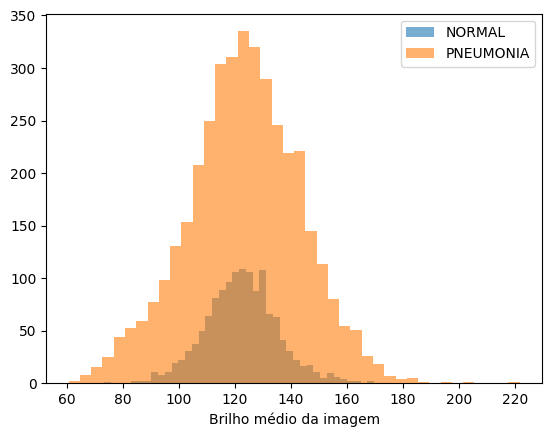

122.4 123.2


In [7]:
# Brilho médio de cada imagem: a média de todos os pixels dela. axis=(1, 2) faz a média na altura e na
# largura, e sobra um número por imagem. Na escala, 0 = preto e 255 = branco.
brilho = X_treino_total.mean(axis=(1, 2))                      # um número por imagem
# hist desenha um histograma. bins=40 divide os valores em 40 faixas. alpha=0.6 deixa as barras
# um pouco transparentes, para ver as duas classes sobrepostas. label é o nome que aparece na legenda.
plt.hist(brilho[y_treino_total == 0], bins=40, alpha=0.6, label='NORMAL')  # distribuição dos NORMAL
plt.hist(brilho[y_treino_total == 1], bins=40, alpha=0.6, label='PNEUMONIA')  # distribuição dos PNEUMONIA
plt.xlabel('Brilho médio da imagem')                           # nome do eixo x
plt.legend()                                                   # mostra a legenda com os nomes das classes
plt.savefig('figuras/pneumonia_brilho.png')                    # salva o gráfico
plt.show()                                                     # mostra o gráfico
brilho_normal = brilho[y_treino_total == 0].mean()             # brilho médio das imagens NORMAL
brilho_pneumonia = brilho[y_treino_total == 1].mean()          # brilho médio das imagens PNEUMONIA
print(round(brilho_normal, 1), round(brilho_pneumonia, 1))     # os dois números vão para o relatório

## B4. Treino, validação e teste

| Parte | Imagens | Para quê |
| --- | --- | --- |
| Treino | 4.181 | a rede aprende com estas imagens |
| Validação | 1.035 | acompanhar o treino e escolher o modelo |
| Teste | 624 | medir o modelo escolhido, só no fim |

**Por que 3 partes?** A validação é o simulado: compara os modelos e escolhe um. O teste é a prova final: mede uma vez só, no fim. A validação sai de dentro do treino (cerca de 20%), porque a pasta `val` tem só 16 imagens.

**Por que separar por paciente, e não por imagem?**

- Muitas crianças têm mais de uma radiografia. Uma delas tem 30.
- Se as imagens de uma criança caem no treino e na validação, a rede pode reconhecer a criança, e não a doença.
- Aí a validação fica fácil demais e escolhe mal o modelo. A célula abaixo mostra o tamanho do problema: no sorteio por imagem, 413 das 1.044 imagens de validação seriam de crianças que também estão no treino.
- Por isso, cada criança fica inteira de um lado só: ou no treino, ou na validação.

**Como a divisão é feita?** Com o `StratifiedGroupKFold`. Ele separa por grupo (o paciente) e mantém a proporção de PNEUMONIA (74%) nas duas partes. A célula também confere que o teste oficial não tem nenhum paciente do treino: os autores da base também separaram assim.

**Por que não usar validação cruzada, como na Parte A?** Seria preciso treinar cada CNN 5 vezes. Uma validação com 1.035 imagens já é estável: um erro muda o recall de NORMAL em menos de 0,004 (1 de 265).

In [8]:
# StratifiedGroupKFold divide os dados em partes, com duas regras:
# group = todas as imagens de um mesmo paciente ficam na mesma parte;
# stratified = cada parte mantém a proporção de PNEUMONIA (74%).
from sklearn.model_selection import StratifiedGroupKFold      # divisão por paciente (scikit-learn)
# n_splits=5: 5 partes; uma delas (20%) vira a validação. shuffle=True sorteia os pacientes; random_state=42 fixa o sorteio.
divisor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)  # o divisor
# split devolve as posições das imagens de treino e de validação. groups diz de qual paciente é cada imagem.
# next(...) pega só a 1ª das 5 divisões: uma validação basta (veja o texto acima).
i_treino, i_val = next(divisor.split(X_treino_total, y_treino_total, groups=pac_treino_total))  # posições
X_treino, y_treino = X_treino_total[i_treino], y_treino_total[i_treino]  # imagens e rótulos de treino
X_val, y_val = X_treino_total[i_val], y_treino_total[i_val]    # imagens e rótulos de validação

# Conferências: quantas imagens têm o mesmo paciente dos dois lados. isin marca essas imagens; sum conta.
print('Imagens com o mesmo paciente dos dois lados:')          # título das 3 conferências
print('  treino x validação, por paciente:', np.isin(pac_treino_total[i_val], pac_treino_total[i_treino]).sum())  # esperado: 0
# Só para comparar: o sorteio por imagem (train_test_split), que não olha o paciente.
from sklearn.model_selection import train_test_split           # sorteio por imagem
# np.arange cria as posições 0, 1, 2, ...; o sorteio devolve as posições de treino e de validação.
i_tr_img, i_val_img = train_test_split(np.arange(len(y_treino_total)), test_size=0.2,
                                       stratify=y_treino_total, random_state=42)  # posições do sorteio por imagem
print('  treino x validação, por imagem:', np.isin(pac_treino_total[i_val_img], pac_treino_total[i_tr_img]).sum(),
      'de', len(i_val_img))                                    # esperado: 413 de 1044
print('  treino x teste oficial:', np.isin(pac_teste, pac_treino_total).sum())  # esperado: 0

# reshape((-1, 128, 128, 1)) acrescenta o canal no fim: a CNN espera (imagens, altura, largura, canais).
# O -1 manda o NumPy calcular sozinho o número de imagens.
# astype('float32') troca os números inteiros (0 a 255) por decimais, o tipo que a rede usa.
# Dividir por 255 deixa cada pixel entre 0 e 1. Valores pequenos deixam o treino da rede mais estável.
X_treino = X_treino.reshape((-1, TAMANHO, TAMANHO, 1)).astype('float32') / 255  # formato da CNN e escala de 0 a 1
X_val = X_val.reshape((-1, TAMANHO, TAMANHO, 1)).astype('float32') / 255  # o mesmo na validação
# O teste parte de X_teste_bruto, que nunca muda. Assim, rodar esta célula de novo não divide por 255 duas vezes.
X_teste = X_teste_bruto.reshape((-1, TAMANHO, TAMANHO, 1)).astype('float32') / 255  # o mesmo no teste
print(X_treino.shape, X_val.shape, X_teste.shape)              # esperado: (4181, 128, 128, 1) (1035, 128, 128, 1) (624, 128, 128, 1)
print(np.bincount(y_treino), np.bincount(y_val))               # esperado: [1076 3105] [265 770]

Imagens com o mesmo paciente dos dois lados:
  treino x validação, por paciente: 0
  treino x validação, por imagem: 413 de 1044
  treino x teste oficial: 0
(4181, 128, 128, 1) (1035, 128, 128, 1) (624, 128, 128, 1)
[1076 3105] [265 770]


## B5. CNN 1: a rede base

A CNN 1 é uma rede pequena e clássica. Ela segue a estrutura do tutorial oficial de CNN do TensorFlow, adaptada para imagens de 128 × 128 × 1 e 2 classes. As outras soluções são comparadas com ela.

| Camada | O que faz | Tamanho na saída |
| --- | --- | --- |
| Entrada | o raio-X em cinza | 128 × 128 × 1 |
| Convolução 1 (32 filtros) | acha padrões simples, como bordas e linhas | 126 × 126 × 32 |
| Max pooling | reduz à metade | 63 × 63 × 32 |
| Convolução 2 (64 filtros) | combina bordas em formas e texturas | 61 × 61 × 64 |
| Max pooling | reduz à metade (61 → 30: arredonda para baixo) | 30 × 30 × 64 |
| Convolução 3 (64 filtros) | combina formas em regiões maiores, como manchas no pulmão | 28 × 28 × 64 |
| Flatten | põe tudo numa fila só | 50.176 números |
| Densa (64 neurônios) | junta os padrões para decidir | 64 |
| Saída (softmax) | dá a chance de cada classe | 2 |

Cada convolução usa filtros de 3 × 3 pixels e perde 1 pixel em cada borda: por isso, 128 vira 126.

**Por que cada parte:**

- **3 convoluções:** cada uma acha padrões um pouco maiores que a anterior: bordas, depois formas, depois regiões do pulmão.
- **2 max pooling:** cada um reduz a imagem à metade. As contas ficam mais leves, e um padrão é achado mesmo se mudar um pouco de lugar.
- **Filtros 32, 64 e 64:** a imagem encolhe, então cada filtro custa menos contas, e dá para usar mais filtros.
- **Camada densa (64):** junta os padrões numa decisão. Ela tem 98% dos 3.267.202 parâmetros da rede.
- **2 saídas com softmax:** uma chance por classe; as duas somam 1.

**Ajustes do treino:**

- `adam`: otimizador que ajusta sozinho o tamanho do passo de cada peso.
- `sparse_categorical_crossentropy`: a perda certa para rótulos 0 e 1 com saída softmax.
- 10 épocas: o bastante para ver nas curvas (B7) se a rede ainda aprende ou já começa a decorar.
- lotes de 32 imagens: o padrão do Keras.
- semente 42: repete os sorteios. Na GPU, os números ainda podem variar um pouco.

In [9]:
# set_random_seed fixa os sorteios (pesos iniciais, ordem das imagens), para o treino se repetir. Na GPU, ainda pode variar um pouco.
tf.keras.utils.set_random_seed(42)                             # semente fixa
cnn1 = models.Sequential()                                     # Sequential: as camadas ficam em pilha, uma depois da outra
# Input diz o formato de cada imagem: 128 x 128 pixels e 1 canal (cinza). Ela não tem pesos para aprender.
cnn1.add(layers.Input(shape=(TAMANHO, TAMANHO, 1)))            # entrada
# Conv2D(32, (3, 3)) cria 32 filtros de 3 x 3 pixels. Cada filtro aprende a achar um padrão (borda, mancha).
# activation='relu' zera os valores negativos; é isso que deixa a rede aprender formas complexas.
cnn1.add(layers.Conv2D(32, (3, 3), activation='relu'))         # 1ª convolução
# MaxPooling2D((2, 2)) fica com o maior valor de cada quadrado 2 x 2: a imagem cai à metade em cada lado.
cnn1.add(layers.MaxPooling2D((2, 2)))                          # reduz à metade
cnn1.add(layers.Conv2D(64, (3, 3), activation='relu'))         # 2ª convolução: 64 filtros, padrões mais complexos
cnn1.add(layers.MaxPooling2D((2, 2)))                          # reduz à metade de novo
cnn1.add(layers.Conv2D(64, (3, 3), activation='relu'))         # 3ª convolução: mais 64 filtros
# Flatten "achata" o resultado (28 x 28 x 64) numa fila só, de 50.176 números, para a camada densa.
cnn1.add(layers.Flatten())                                     # vira vetor
# Dense(64): camada densa com 64 neurônios, cada um ligado a todos os números da fila. Ela combina os padrões.
cnn1.add(layers.Dense(64, activation='relu'))                  # camada densa
# Dense(2) com softmax: 2 saídas, uma por classe. O softmax transforma as saídas em chances que somam 1.
cnn1.add(layers.Dense(2, activation='softmax'))                # 2 saídas: NORMAL e PNEUMONIA
# compile prepara o treino. optimizer='adam' é o método que ajusta os pesos a cada passo.
# 'sparse_categorical_crossentropy' é a perda (o erro) usada com rótulos inteiros (0 e 1) e saída softmax.
# metrics=['accuracy'] mostra a acurácia durante o treino.
cnn1.compile(optimizer='adam',                                 # otimizador Adam
             loss='sparse_categorical_crossentropy',           # função de perda
             metrics=['accuracy'])                             # métrica exibida
# summary mostra cada camada, o formato da saída dela e quantos parâmetros (pesos) a rede aprende.
cnn1.summary()                                                 # total esperado: 3.267.202 parâmetros
# fit treina a rede e guarda o histórico (perda e acurácia de cada época) em hist1.
hist1 = cnn1.fit(X_treino, y_treino,                           # treina só com o treino
                 epochs=10,                                    # época = uma passada por todas as imagens de treino; são 10 passadas
                 batch_size=32,                                # a rede ajusta os pesos a cada grupo de 32 imagens
                 # validation_data: depois de cada época, mede a rede na validação, sem treinar com ela.
                 validation_data=(X_val, y_val))               # validação SEPARADA (o teste fica guardado)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     3,211,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,267,202 (12.46 MB)

 Trainable params: 3,267,202 (12.46 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 19s 67ms/step - accuracy: 0.8859 - loss: 0.2650 - val_accuracy: 0.9382 - val_loss: 0.1618
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9610 - loss: 0.1048 - val_accuracy: 0.9691 - val_loss: 0.0924
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9651 - loss: 0.0963 - val_accuracy: 0.9720 - val_loss: 0.0928
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9737 - loss: 0.0723 - val_accuracy: 0.9758 - val_loss: 0.0875
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9756 - loss: 0.0643 - val_accuracy: 0.9749 - val_loss: 0.1113
Epoch 6/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9806 - loss: 0.0547 - val_accuracy: 0.9768 - val_loss: 0.1054
Epoch 7/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9818 - loss: 0.0480 - val_accuracy: 0.9739 - val_loss: 0.1049
Epoch 8/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9890 - loss: 0.0340 - val_acc

## B6. CNN 2: mais filtros, mais pooling e Dropout

A CNN 2 parte da CNN 1 e muda 3 coisas. O pooling a mais e o Dropout atacam o **overfitting**: a rede decorar o treino em vez de aprender o que vale para imagens novas. Os 128 filtros dão mais capacidade à rede; o pooling a mais compensa esse aumento.

| O que muda | CNN 1 | CNN 2 | Por quê |
| --- | --- | --- | --- |
| Filtros da 3ª convolução | 64 | 128 | mais padrões diferentes na camada que vê as regiões maiores |
| Pooling depois da 3ª convolução | não | sim | a imagem cai de 28 × 28 para 14 × 14 antes da camada densa |
| Dropout antes da saída | não | 50% | a rede não pode depender de poucos neurônios |
| Total de parâmetros | 3.267.202 | 1.698.498 | cerca de metade (52%) |

**Por que tão menos parâmetros?** O pooling a mais encolhe a imagem antes da camada densa: o Flatten cai de 50.176 para 25.088 números. Com menos parâmetros, sobra menos espaço para decorar.

**Como o Dropout funciona?** A cada passo do treino, cada neurônio da camada densa tem 50% de chance de ser desligado. Assim, a rede precisa espalhar o que aprende. Na hora de prever, todos ficam ligados. 50% é o valor indicado no artigo do Dropout (Srivastava et al., 2014).

**Comparação justa:** a mesma semente, as mesmas 10 épocas e os mesmos lotes de 32 imagens da CNN 1.

**Um limite:** como as 3 mudanças entram juntas, não dá para saber qual delas ajudou mais.

In [10]:
tf.keras.utils.set_random_seed(42)                             # mesma semente da CNN 1: comparação justa
cnn2 = models.Sequential()                                     # modelo em pilha
cnn2.add(layers.Input(shape=(TAMANHO, TAMANHO, 1)))            # entrada, igual à CNN 1
cnn2.add(layers.Conv2D(32, (3, 3), activation='relu'))         # igual à CNN 1
cnn2.add(layers.MaxPooling2D((2, 2)))                          # igual à CNN 1
cnn2.add(layers.Conv2D(64, (3, 3), activation='relu'))         # igual à CNN 1
cnn2.add(layers.MaxPooling2D((2, 2)))                          # igual à CNN 1
# A partir daqui vêm as mudanças. A 3ª convolução tem 128 filtros, em vez de 64: mais padrões diferentes.
cnn2.add(layers.Conv2D(128, (3, 3), activation='relu'))        # NOVO: 128 filtros
# Um pooling a mais: a imagem cai de 28 x 28 para 14 x 14, e a fila que entra na camada densa fica menor.
cnn2.add(layers.MaxPooling2D((2, 2)))                          # NOVO: mais um pooling
cnn2.add(layers.Flatten())                                     # vira vetor: 14 x 14 x 128 = 25.088 números (eram 50.176)
cnn2.add(layers.Dense(64, activation='relu'))                  # camada densa, igual à CNN 1
# Dropout(0.5) desliga, ao acaso, 50% dos neurônios a cada passo do treino. Assim a rede não depende de
# poucos neurônios e decora menos o treino (menos overfitting). Na hora de prever, todos ficam ligados.
cnn2.add(layers.Dropout(0.5))                                  # NOVO: Dropout de 50%
cnn2.add(layers.Dense(2, activation='softmax'))                # 2 saídas, igual à CNN 1
cnn2.compile(optimizer='adam',                                 # mesmo otimizador
             loss='sparse_categorical_crossentropy',           # mesma função de perda
             metrics=['accuracy'])                             # mesma métrica
cnn2.summary()                                                 # total esperado: 1.698.498 parâmetros (cerca de metade da CNN 1)
hist2 = cnn2.fit(X_treino, y_treino,                           # treina só com o treino
                 epochs=10,                                    # mesmas 10 épocas: comparação justa
                 batch_size=32,                                # 32 imagens por passo
                 validation_data=(X_val, y_val))               # validação separada

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │     1,605,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,698,498 (6.48 MB)

 Trainable params: 1,698,498 (6.48 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 12s 55ms/step - accuracy: 0.7773 - loss: 0.4352 - val_accuracy: 0.9121 - val_loss: 0.2654
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.9213 - loss: 0.2659 - val_accuracy: 0.9488 - val_loss: 0.2378
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9421 - loss: 0.2265 - val_accuracy: 0.9575 - val_loss: 0.2030
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.9488 - loss: 0.1974 - val_accuracy: 0.9536 - val_loss: 0.1947
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9505 - loss: 0.1803 - val_accuracy: 0.9594 - val_loss: 0.1669
Epoch 6/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.9560 - loss: 0.1617 - val_accuracy: 0.9633 - val_loss: 0.1685
Epoch 7/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9608 - loss: 0.1450 - val_accuracy: 0.9643 - val_loss: 0.1533
Epoch 8/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9636 - loss: 0.1333 - val_acc

## B7. Curvas de treino

As curvas mostram, época a época, a acurácia e a perda (o erro) no treino e na validação. Elas respondem: a rede aprendeu ou decorou?

**Como ler:**

- **Aprendeu:** as duas perdas caem e ficam próximas.
- **Decorou (overfitting):** a perda de treino continua caindo, mas a de validação para de cair ou sobe.
- Subidas e descidas pequenas de uma época para outra são normais. O que importa é a tendência.

**Dois cuidados:**

- Na CNN 2, a curva de treino é medida com o Dropout ligado, o que faz o treino parecer pior. Por isso, o B12 mede de novo a distância entre treino e validação, com o Dropout desligado.
- A rede usada depois é a da 10ª época, não a da melhor época.

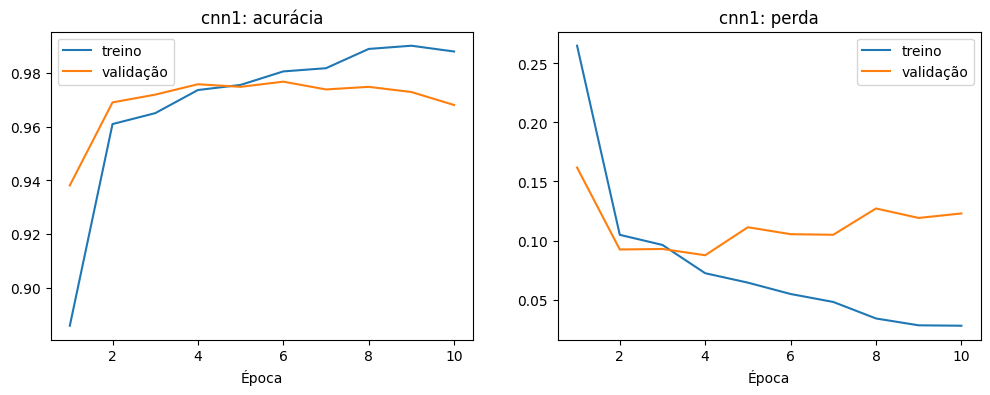

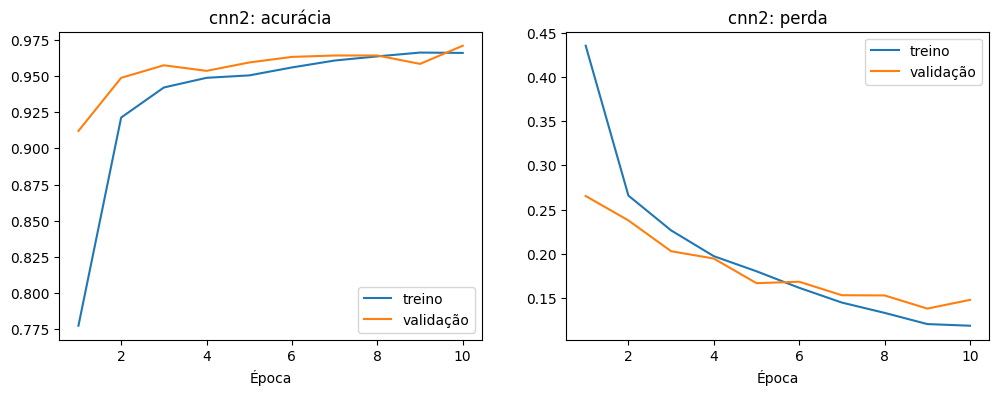

In [11]:
# Função que desenha as curvas de um treino. Recebe o histórico (hist) e o nome da rede (título e arquivo).
def plotar_curvas(hist, nome):                                 # desenha a acurácia e a perda de um treino
    # As épocas vão de 1 a 10, como nos textos do B12. range(1, n + 1) gera 1, 2, ..., n.
    epocas = range(1, len(hist.history['loss']) + 1)           # eixo x
    plt.figure(figsize=(12, 4))                                # figura larga: 2 gráficos
    plt.subplot(1, 2, 1)                                       # gráfico da esquerda
    # hist.history é um dicionário com uma lista de valores por época: 'accuracy' (treino) e 'val_accuracy' (validação).
    plt.plot(epocas, hist.history['accuracy'], label='treino')         # acurácia no treino
    plt.plot(epocas, hist.history['val_accuracy'], label='validação')  # acurácia na validação
    plt.title(nome + ': acurácia')                             # título
    plt.xlabel('Época')                                        # eixo x
    plt.legend()                                               # legenda
    plt.subplot(1, 2, 2)                                       # gráfico da direita
    # 'loss' e 'val_loss' são a perda (o erro) no treino e na validação. Quanto menor, melhor.
    plt.plot(epocas, hist.history['loss'], label='treino')             # perda no treino
    plt.plot(epocas, hist.history['val_loss'], label='validação')      # perda na validação
    plt.title(nome + ': perda')                                # título
    plt.xlabel('Época')                                        # eixo x
    plt.legend()                                               # legenda
    plt.savefig('figuras/pneumonia_curvas_' + nome + '.png')   # salva; o nome do arquivo leva o nome da rede
    plt.show()                                                 # mostra o gráfico

plotar_curvas(hist1, 'cnn1')                                   # curvas da CNN 1
plotar_curvas(hist2, 'cnn2')                                   # curvas da CNN 2

## B8. Solução sem rede neural: PCA + Random Forest

**Por que comparar com um modelo clássico?** Para saber se a CNN vale o esforço. Se um modelo mais simples chegar perto, a CNN não se justifica.

**Como a imagem vira tabela:** cada imagem é reduzida para 64 × 64 pixels e vira uma linha, com um pixel por coluna: 4.096 colunas. Com 128 × 128, seriam 16.384 colunas, e o treino ficaria bem mais lento.

**As 3 etapas do Pipeline:**

1. **StandardScaler:** deixa cada pixel com média 0 e desvio 1, para todos entrarem com o mesmo peso no PCA.
2. **PCA (95%):** pixels vizinhos repetem informação, como raio, perímetro e área na Parte A. O PCA junta essa repetição em poucas componentes.
3. **Random Forest:** 300 árvores, com `class_weight='balanced'`. Como 74% do treino é pneumonia, o peso maior na classe NORMAL evita que o modelo chame quase todos de doentes.

O Pipeline garante que o StandardScaler e o PCA aprendam só com o treino.

**O que esperar:** na tabela, o Random Forest perde a noção de vizinhança entre os pixels; a CNN olha pedaços da imagem. Por isso, esperamos que a CNN vá melhor. O Random Forest também vê menos detalhe (64 × 64) que as CNNs.

In [12]:
from sklearn.pipeline import Pipeline                          # Pipeline: junta etapas num só objeto
from sklearn.preprocessing import StandardScaler               # padronização: média 0 e desvio padrão 1 em cada coluna
from sklearn.decomposition import PCA                          # PCA: resume muitas colunas parecidas em poucas componentes
from sklearn.ensemble import RandomForestClassifier            # Random Forest

# O Random Forest trabalha com tabelas: uma linha por exemplo, uma coluna por medida.
# Esta função transforma cada imagem numa linha de tabela.
def achatar(X):                                                # recebe as imagens e devolve a tabela
    # Reduz cada imagem para 64 x 64, para a tabela ficar menor e o treino mais rápido.
    menores = [cv2.resize(img, (64, 64), interpolation=cv2.INTER_AREA) for img in X]  # imagens de 64 x 64
    # reshape(len(X), -1): uma linha por imagem; o -1 calcula sozinho o número de colunas (64 x 64 = 4.096).
    return np.array(menores).reshape(len(X), -1)               # cada imagem vira uma linha de 4.096 pixels

rf_pca = Pipeline([('escala', StandardScaler()),               # 1ª etapa: padronização (o fit usa só o treino)
                   # random_state=42 fixa o sorteio interno do PCA.
                   ('pca', PCA(n_components=0.95, random_state=42)),  # 2ª etapa: guarda 95% da informação
                   ('modelo', RandomForestClassifier(n_estimators=300,  # 300 árvores: mais árvores dão um voto mais estável
                                                     class_weight='balanced',  # mais peso à classe menor (NORMAL): 74% do treino é pneumonia
                                                     random_state=42,  # mesmo sorteio sempre
                                                     n_jobs=-1))])  # usa todos os núcleos do processador
rf_pca.fit(achatar(X_treino), y_treino)                        # treina só com o treino
print('Componentes:', rf_pca.named_steps['pca'].n_components_)  # quantas componentes sobraram das 4.096 colunas

Componentes: 246


## B9. Comparar na validação e escolher o modelo

O modelo final é escolhido aqui, na validação, **antes de olhar o teste**. A célula calcula 4 métricas para cada modelo e aplica a regra de escolha sozinha.

**As métricas:** recall de PNEUMONIA (a principal), recall de NORMAL (a trava), F1 e acurácia (só de apoio, porque engana quando as classes são desequilibradas).

**Por que uma trava no recall de NORMAL?** Um modelo que chamasse todos de doentes teria recall de PNEUMONIA igual a 1,0 e não serviria para nada: todo exame normal viraria um alarme falso.

**A regra:**

1. **Trava:** descarta quem tem recall de NORMAL abaixo de 0,80, ou seja, quem erra mais de 1 em cada 5 exames normais. O limite de 0,80 é uma escolha nossa.
2. **Principal:** entre os que sobram, vence o maior recall de PNEUMONIA.
3. **Empate:** diferenças de até 0,02 contam como empate (cerca de 15 das 770 pneumonias da validação). No empate, vence quem erra menos os exames normais.
4. **Exceção:** se nenhum modelo passar da trava, vence o que chegar mais perto dela.

Cada modelo dá uma chance de PNEUMONIA. Com 0,5 ou mais, a imagem conta como PNEUMONIA (o limiar padrão).

In [13]:
from sklearn.metrics import recall_score, f1_score, accuracy_score  # métricas, as mesmas da Parte A

# Função que devolve a chance de PNEUMONIA dada por um modelo, a partir do nome dele.
# Ela esconde a diferença entre os modelos: as CNNs recebem imagens; o Random Forest recebe a tabela.
def prob_pneumonia(nome, X):                                   # recebe o nome do modelo e as imagens
    if nome == 'PCA + RF':                                     # é o Random Forest?
        # predict_proba devolve 2 colunas: chance de NORMAL (0) e de PNEUMONIA (1). [:, 1] pega a coluna 1.
        return rf_pca.predict_proba(achatar(X))[:, 1]          # chance de PNEUMONIA
    rede = cnn1 if nome == 'CNN 1' else cnn2                   # escolhe a CNN pelo nome
    # predict devolve as 2 saídas do softmax de cada imagem. verbose=0 esconde a barra de progresso.
    return rede.predict(X, verbose=0)[:, 1]                    # coluna 1 = chance de PNEUMONIA

linhas = []                                                    # lista vazia: uma linha de resultado por modelo
for nome in ['CNN 1', 'CNN 2', 'PCA + RF']:                    # os 3 modelos
    # Limiar de 0,5: chance de 0,5 ou mais = PNEUMONIA (1). astype(int) troca True e False por 1 e 0.
    pred = (prob_pneumonia(nome, X_val) >= 0.5).astype(int)    # previsões na validação
    linhas.append({'modelo': nome,                             # nome do modelo
                   'recall_PNEUMONIA': recall_score(y_val, pred),  # métrica principal: doentes encontrados
                   # pos_label=0 calcula o recall da classe 0 (NORMAL): quantos saudáveis o modelo acertou.
                   'recall_NORMAL': recall_score(y_val, pred, pos_label=0),  # a trava
                   'f1': f1_score(y_val, pred),                # equilíbrio entre precisão e recall
                   'acuracia': accuracy_score(y_val, pred)})   # acerto geral (apoio)
resultado_val = pd.DataFrame(linhas).set_index('modelo').round(3)  # tabela, como na Parte A

# Regra de escolha. Passo 1, a trava: fica só quem acerta pelo menos 80% dos saudáveis
# (ou seja, erra no máximo 1 em cada 5 exames normais).
passaram = resultado_val[resultado_val['recall_NORMAL'] >= 0.80]  # filtro da tabela
todos_na_trava = len(passaram) == 0                            # True se nenhum modelo passou da trava
if not todos_na_trava:                                         # caso normal: pelo menos um passou
    # Passo 2: o maior recall de PNEUMONIA entre os que passaram. max devolve o maior valor da coluna.
    melhor = passaram['recall_PNEUMONIA'].max()                # maior recall de PNEUMONIA
    # Passo 3: empate. Até 0,02 de diferença (cerca de 15 das 770 pneumonias da validação) conta como empate.
    empatados = passaram[passaram['recall_PNEUMONIA'] >= melhor - 0.02]  # os empatados com o melhor
    # sort_values com 2 colunas: ordena pelo recall de NORMAL e, se ainda houver empate, pelo de PNEUMONIA.
    # index[0] pega o nome do modelo que ficou em primeiro.
    FINAL = empatados.sort_values(['recall_NORMAL', 'recall_PNEUMONIA'], ascending=False).index[0]  # vence quem erra menos os saudáveis
else:                                                          # nenhum passou da trava
    # Vence o que chegou mais perto dela: o maior recall de NORMAL.
    FINAL = resultado_val.sort_values(['recall_NORMAL', 'recall_PNEUMONIA'], ascending=False).index[0]  # o mais perto da trava
print('Modelo final:', FINAL)                                  # escolhido ANTES de olhar o teste
resultado_val.sort_values('recall_PNEUMONIA', ascending=False)  # a tabela, com o maior recall em cima

Modelo final: CNN 2


,recall_PNEUMONIA,recall_NORMAL,f1,acuracia
modelo,,,,
PCA + RF,0.996,0.475,0.915,0.863
CNN 1,0.984,0.921,0.979,0.968
CNN 2,0.978,0.951,0.980,0.971


## B10. Avaliar no teste

Agora o teste é usado pela primeira vez: 624 imagens que nenhum modelo viu (234 NORMAL e 390 PNEUMONIA). Em outros hospitais, o resultado pode ser pior.

**O que olhar:**

- **Relatório por classe:** precisão, recall e F1 de NORMAL e de PNEUMONIA.
- **Matriz de confusão:** os acertos e os 2 tipos de erro. O falso negativo (um doente chamado de NORMAL) é o mais grave.
- **Curva ROC e AUC:** mostram se o modelo separa as classes em todos os limiares, não só no 0,5. AUC de 0,5 é um chute; 1,0 é a separação perfeita.

**Compare pelo recall:** o teste tem 62,5% de PNEUMONIA, contra 74% no treino. A acurácia muda com essa proporção; o recall de cada classe, não.

**A última célula** mede também os outros dois modelos, só para o relatório. Isso não muda a escolha: se trocássemos de modelo depois de ver o teste, ele deixaria de ser uma medida justa.

Modelo final: CNN 2
              precision    recall  f1-score   support

      NORMAL      0.950     0.406     0.569       234
   PNEUMONIA      0.735     0.987     0.842       390

    accuracy                          0.769       624
   macro avg      0.842     0.697     0.706       624
weighted avg      0.815     0.769     0.740       624



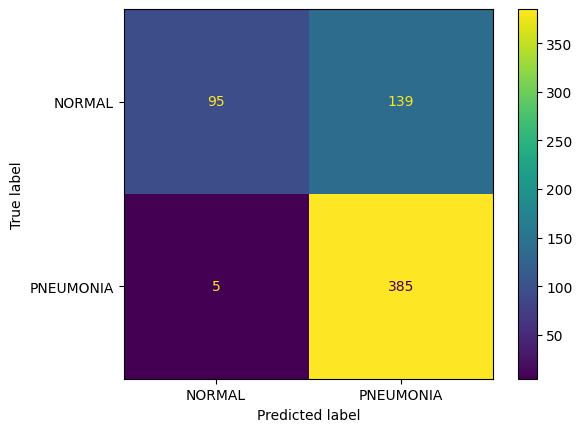

In [14]:
# Métricas e gráficos do teste: relatório por classe, matriz de confusão, curva ROC e AUC.
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc  # métricas, matriz e curva ROC
print('Modelo final:', FINAL)                                  # escolhido no B9, antes do teste
prob_teste = prob_pneumonia(FINAL, X_teste)                    # chance de PNEUMONIA de cada imagem do teste
pred_teste = (prob_teste >= 0.5).astype(int)                   # classe prevista, com o limiar padrão de 0,5
# target_names=CLASSES dá nome às classes 0 e 1. digits=3 mostra 3 casas decimais.
print(classification_report(y_teste, pred_teste, target_names=CLASSES, digits=3))  # precisão, recall e F1 por classe
mc = confusion_matrix(y_teste, pred_teste)                     # 2 x 2: linhas = classe real, colunas = classe prevista
# values_format='d' mostra os números como inteiros.
ConfusionMatrixDisplay(confusion_matrix=mc, display_labels=CLASSES).plot(values_format='d')  # desenha a matriz
plt.savefig('figuras/pneumonia_matriz.png')                    # salva o gráfico
plt.show()                                                     # mostra o gráfico

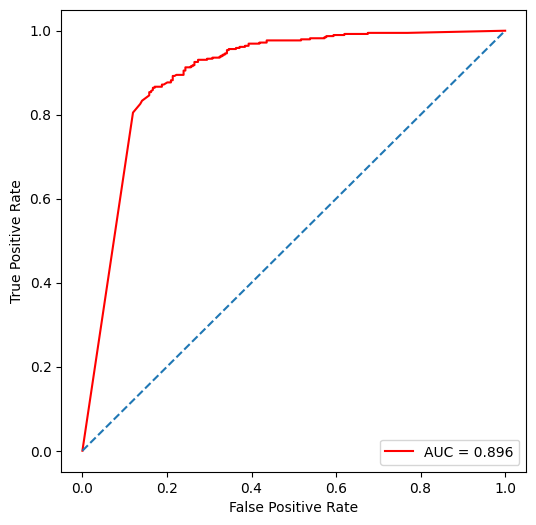

In [15]:
# Para cada limiar possível, roc_curve calcula a taxa de falsos positivos (fpr) e a de verdadeiros positivos (tpr).
fpr, tpr, limiares = roc_curve(y_teste, prob_teste)            # pontos da curva
auc_teste = auc(fpr, tpr)                                      # área sob a curva: 0,5 = chute; 1 = separação perfeita
plt.figure(figsize=(6, 6))                                     # figura quadrada
plt.plot(fpr, tpr, color='red', label='AUC = %0.3f' % auc_teste)  # a curva; '%0.3f' escreve a AUC com 3 casas
plt.plot([0, 1], [0, 1], linestyle='--')                       # linha tracejada: o resultado de um chute ao acaso
plt.xlabel('False Positive Rate')                              # eixo x: taxa de falsos positivos
plt.ylabel('True Positive Rate')                               # eixo y: taxa de verdadeiros positivos (o recall)
plt.legend(loc='lower right')                                  # legenda no canto de baixo, à direita
plt.savefig('figuras/pneumonia_roc.png')                       # salva o gráfico
plt.show()                                                     # mostra o gráfico

In [16]:
# Mede os 3 modelos no teste, só para comparar no relatório. A escolha do modelo já foi feita na validação.
matrizes = {}                                                  # dicionário vazio: nome do modelo -> matriz de confusão
for nome in ['CNN 1', 'CNN 2', 'PCA + RF']:                    # os 3 modelos
    p = (prob_pneumonia(nome, X_teste) >= 0.5).astype(int)     # previsões no teste, com limiar de 0,5
    matrizes[nome] = confusion_matrix(y_teste, p)              # guarda a matriz com o nome do modelo
    # tolist() transforma a matriz em lista, para caber numa linha. V = verdadeiro, F = falso,
    # N = negativo (NORMAL), P = positivo (PNEUMONIA).
    print(nome, matrizes[nome].tolist())                       # [[VN, FP], [FN, VP]]

CNN 1 [[58, 176], [1, 389]]
CNN 2 [[95, 139], [5, 385]]
PCA + RF [[15, 219], [0, 390]]


## B11. Interpretar

O médico precisa entender **onde** o modelo olha. Além da matriz de confusão do B10, usamos 3 ferramentas.

**1. Grade de previsões:** 25 imagens do teste, com a classe prevista e a real. Azul é acerto; vermelho é erro.

**2. Mapa de oclusão** (Zeiler e Fergus, 2014): mostra quais pedaços da imagem pesaram na decisão.

- A imagem é dividida em 8 × 8 quadrados, cada um com 16 × 16 pixels.
- Cada quadrado é coberto, um por vez, com o cinza médio da imagem.
- Medimos quanto a certeza de PNEUMONIA cai. Quanto mais cai, mais vermelho fica o quadrado.
- A certeza é medida pela log-chance, que continua mudando mesmo quando a chance já está em 1,0 (veja o comentário do código).

É parecido com o SHAP da Parte A: explica uma imagem por vez. O SHAP direto nos 16.384 pixels seria bem mais lento; a oclusão testa só 64 quadrados.

**3. Peso no centro:** a última célula mede, em até 20 acertos, quanto do peso do mapa fica no miolo da imagem, onde estão os pulmões. O miolo ocupa 56% da área. Usamos 70% como sinal de que o peso se concentra no centro. É uma regra nossa, e ela não prova que o modelo olha a doença: o coração também fica no centro.

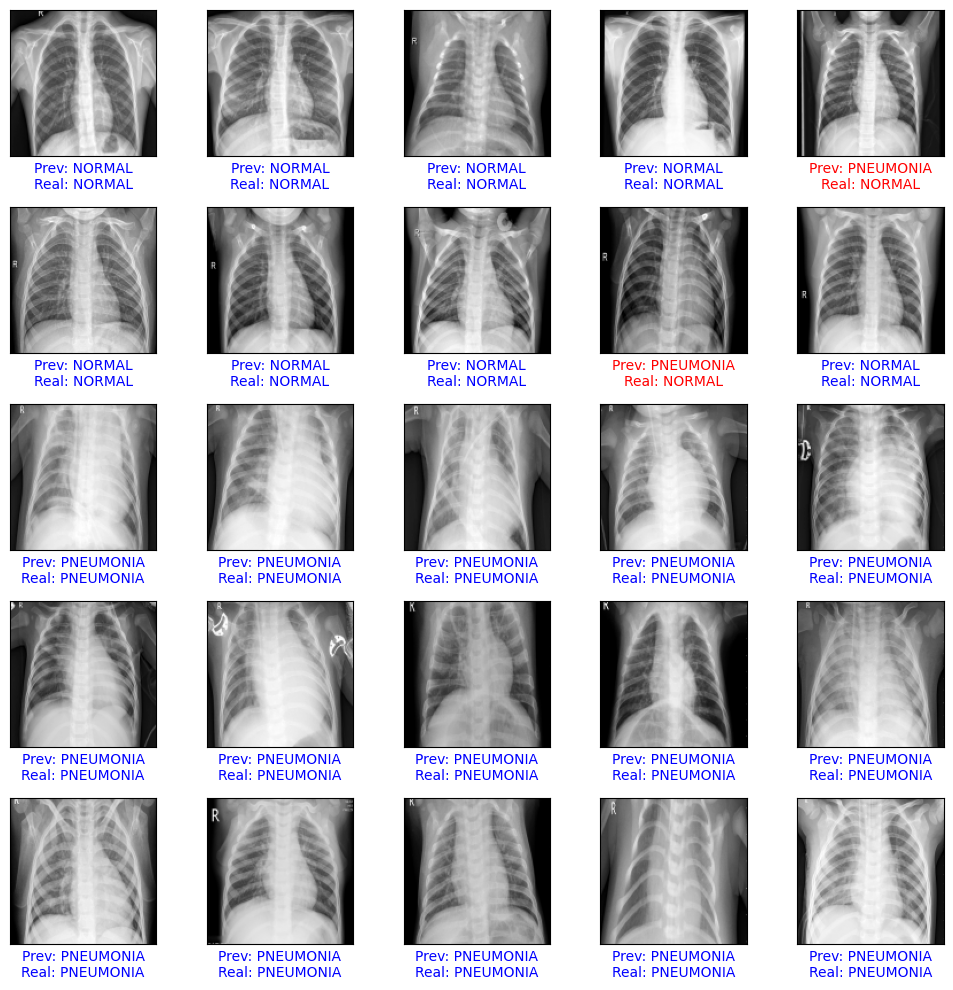

In [17]:
plt.figure(figsize=(10, 10))                                   # figura grande
for i in range(25):                                            # 25 imagens do teste
    # O teste também está em ordem (234 NORMAL, depois 390 PNEUMONIA). Pular de 25 em 25 pega as duas classes.
    j = i * 25                                                 # posição da imagem
    plt.subplot(5, 5, i + 1)                                   # grade 5 x 5
    plt.xticks([])                                             # tira as marcas do eixo x
    plt.yticks([])                                             # tira as marcas do eixo y
    # reshape(TAMANHO, TAMANHO) tira o canal (128, 128, 1 vira 128, 128), porque o imshow desenha matrizes 2D.
    plt.imshow(X_teste[j].reshape(TAMANHO, TAMANHO), cmap='gray')  # a imagem
    cor = 'blue' if pred_teste[j] == y_teste[j] else 'red'     # azul = acertou, vermelho = errou
    # O \n quebra a linha da legenda: em cima, a classe prevista; embaixo, a real.
    plt.xlabel(f'Prev: {CLASSES[pred_teste[j]]}\nReal: {CLASSES[y_teste[j]]}', color=cor)  # previsto e real
# tight_layout abre espaço entre as linhas, para a legenda de 2 linhas não ficar escondida.
plt.tight_layout()                                             # ajusta os espaços
plt.savefig('figuras/pneumonia_grade.png')                     # salva o gráfico
plt.show()                                                     # mostra o gráfico

Falsos negativos: 5 | Falsos positivos: 139


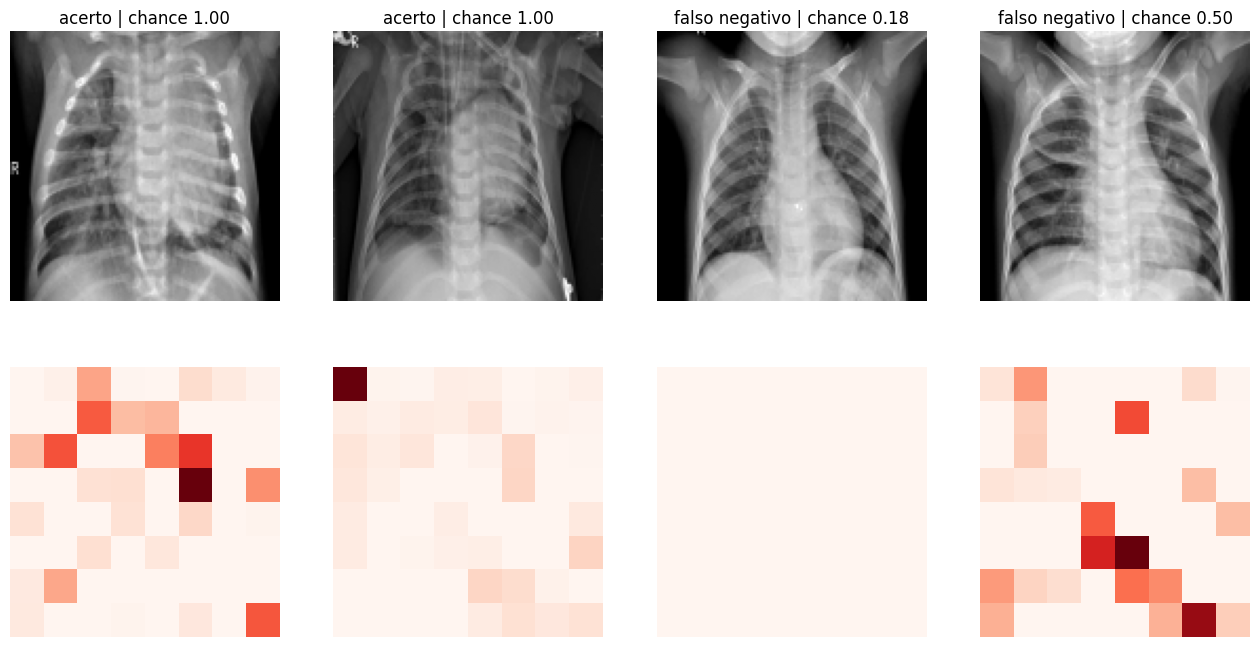

In [18]:
# np.where devolve, numa tupla, as posições onde a condição é verdadeira; o [0] tira a lista de dentro dela.
# O & quer dizer "e".
fn = np.where((y_teste == 1) & (pred_teste == 0))[0]           # falsos negativos: doentes que o modelo chamou de NORMAL
fp = np.where((y_teste == 0) & (pred_teste == 1))[0]           # falsos positivos: saudáveis chamados de PNEUMONIA
vp = np.where((y_teste == 1) & (pred_teste == 1))[0]           # verdadeiros positivos: doentes que o modelo achou
print('Falsos negativos:', len(fn), '| Falsos positivos:', len(fp))  # os dois tipos de erro

# O mapa usa a log-chance: log(chance de PNEUMONIA) - log(chance de NORMAL). Quando a rede tem muita
# certeza, a chance arredonda para exatamente 1,0 e deixa de mudar; a log-chance continua mudando.
def log_chance(X):                                             # log-chance de PNEUMONIA do modelo final, para cada imagem
    if FINAL == 'PCA + RF':                                    # o Random Forest recebe a tabela de pixels
        p = rf_pca.predict_proba(achatar(X))                   # 2 colunas: NORMAL e PNEUMONIA
    else:                                                      # uma das CNNs
        p = (cnn1 if FINAL == 'CNN 1' else cnn2).predict(X, verbose=0)  # 2 colunas: NORMAL e PNEUMONIA
    # float64 dá mais precisão. clip troca valores menores que 1e-12 por 1e-12, porque log(0) não existe.
    p = np.clip(p.astype('float64'), 1e-12, 1)                 # evita log(0)
    return np.log(p[:, 1]) - np.log(p[:, 0])                   # positivo = puxa para PNEUMONIA

# Mapa de oclusão (Zeiler e Fergus, 2014): cobre um quadrado da imagem por vez e mede quanto a
# log-chance de PNEUMONIA cai. Se cair muito, aquele pedaço era importante para a decisão.
def mapa_oclusao(img, lado=16):                                # lado = tamanho do quadrado coberto, em pixels
    # img[np.newaxis] acrescenta uma dimensão: o modelo espera um grupo de imagens, mesmo que seja uma só.
    base = log_chance(img[np.newaxis])[0]                      # log-chance com a imagem inteira
    n = TAMANHO // lado                                        # quadrados por linha: 128 / 16 = 8 (// é a divisão inteira)
    copias = []                                                # cópias da imagem, cada uma com um quadrado coberto
    for i in range(n):                                         # linhas da grade
        for j in range(n):                                     # colunas da grade
            c = img.copy()                                     # copy faz uma cópia nova, para não estragar a imagem original
            # Cobre o quadrado da linha i e da coluna j com o cinza médio da imagem. Um cinza neutro
            # apaga a informação sem criar uma mancha preta ou branca, que o modelo estranharia.
            c[i*lado:(i+1)*lado, j*lado:(j+1)*lado] = img.mean()  # cobre o quadrado
            copias.append(c)                                   # guarda a cópia
    cobertas = log_chance(np.array(copias))                    # log-chance das 64 cópias, de uma vez só
    # base - cobertas = quanto a log-chance caiu em cada cópia. reshape(n, n) arruma os 64 valores numa grade 8 x 8.
    return (base - cobertas).reshape(n, n)                     # valor alto = aquele pedaço empurrava para PNEUMONIA

escolhidas = list(vp[:2]) + list(fn[:2])                       # 2 acertos e até 2 falsos negativos (se houver)
# 4 polegadas de largura por imagem; max(1, ...) evita uma figura de largura zero se a lista ficar vazia.
plt.figure(figsize=(4 * max(1, len(escolhidas)), 8))           # 2 linhas: raio-X em cima, mapa embaixo
for k, j in enumerate(escolhidas):                             # k = posição na figura; j = posição da imagem no teste
    mapa = mapa_oclusao(X_teste[j])                            # calcula o mapa (8 x 8 quadrados)
    plt.subplot(2, len(escolhidas), k + 1)                     # linha de cima
    plt.imshow(X_teste[j].reshape(TAMANHO, TAMANHO), cmap='gray')  # o raio-X
    # O título diz se foi acerto ou falso negativo e a chance de PNEUMONIA, com 2 casas decimais (:.2f).
    plt.title(('acerto' if pred_teste[j] == 1 else 'falso negativo') + f' | chance {prob_teste[j]:.2f}')  # legenda
    plt.axis('off')                                            # sem eixos
    plt.subplot(2, len(escolhidas), len(escolhidas) + k + 1)   # linha de baixo, mesma coluna
    # cmap='Reds': quanto mais vermelho, mais aquele pedaço pesou. np.maximum(mapa, 0) zera os pedaços que
    # baixavam a chance (ficam brancos). vmax com um mínimo de 1e-9 evita erro quando o mapa inteiro é zero.
    plt.imshow(np.maximum(mapa, 0), cmap='Reds', vmin=0, vmax=max(mapa.max(), 1e-9))  # o mapa de oclusão
    plt.axis('off')                                            # sem eixos
plt.savefig('figuras/pneumonia_oclusao.png')                   # salva o gráfico
plt.show()                                                     # mostra o gráfico

In [19]:
# Mede, em até 20 acertos, quanto do peso do mapa fica no centro da imagem, onde ficam os pulmões.
centro = np.zeros((8, 8), bool)                                # grade 8 x 8 cheia de False (bool = verdadeiro ou falso)
# [1:7, 1:7] marca como True o miolo 6 x 6, tirando 1 quadrado de cada borda: 36 de 64 quadrados = 56% da área.
centro[1:7, 1:7] = True                                        # o miolo, onde ficam os pulmões
pesos_centro = []                                              # fração do peso no centro, imagem a imagem
for j in vp[:20]:                                              # 20 acertos de PNEUMONIA
    # np.maximum(..., 0) troca os negativos por 0: conta só o que empurrava para PNEUMONIA.
    m = np.maximum(mapa_oclusao(X_teste[j]), 0)                # mapa só com os valores positivos
    if m.sum() > 0:                                            # o mapa tem algum peso? (evita dividir por zero)
        # m[centro] pega só os quadrados do miolo. Dividir pela soma total dá a fração do peso no centro.
        pesos_centro.append(m[centro].sum() / m.sum())         # fração do peso no centro
n_mapas = len(pesos_centro)                                    # quantos mapas entraram na conta
peso_centro = np.mean(pesos_centro) if pesos_centro else 0     # média dos mapas (0 se a lista ficar vazia)
# :.0% escreve a fração como porcentagem, sem casas decimais. O limite de 70% é uma regra nossa:
# fica bem acima dos 56% que o centro teria se o peso estivesse espalhado por igual.
print(f'Peso no centro da imagem: {peso_centro:.0%}, em {n_mapas} mapas')  # acima de 70% = o peso se concentra no centro

Peso no centro da imagem: 53%, em 15 mapas


## B12. Textos para o relatório

Esta célula escreve os parágrafos da Parte B para o relatório, já com os números desta execução. Os números mudam um pouco a cada execução na GPU, e copiar dezenas deles à mão é fácil de errar.

**Como usar:** cada trecho começa com `RELATÓRIO ·` e o nome do lugar dele no relatório, como `3.4 · Resultado no teste`. No relatório, o lugar está marcado entre colchetes com o mesmo nome. Troque os colchetes pelo trecho.

A célula também mede a distância entre a acurácia de treino e a de validação de cada CNN, com o Dropout desligado (veja B7).

In [20]:
# Esta célula escreve os textos da Parte B para o relatório, já com os números desta execução.
# As funções abaixo cuidam do português: vírgula decimal, singular e plural, e frases com zero.
def br(v, casas=3):                                            # número no formato brasileiro: 0,943
    # f'{v:.{casas}f}' escreve v com o número de casas pedido; replace troca o ponto pela vírgula.
    return f'{v:.{casas}f}'.replace('.', ',')                  # troca o ponto pela vírgula
def mil(n):                                                    # inteiro com ponto de milhar: 1.341
    # f'{n:,}' escreve 1,341 (padrão americano); replace troca pela forma brasileira, 1.341.
    return f'{int(n):,}'.replace(',', '.')                     # troca a vírgula pelo ponto
def casos(n, um, varios):                                      # singular ou plural: 1 caso, 2 casos
    return f'{n} {um if n == 1 else varios}'                   # o número e a palavra certa
def deixou(n):                                                 # frase dos falsos negativos, com o zero tratado
    if n == 0:                                                 # nenhum doente perdido?
        return 'não deixou passar nenhuma pneumonia'           # frase com o zero
    return f'deixou passar {casos(n, "pneumonia", "pneumonias")}'  # frase com o número
def alarmes(n):                                                # frase dos falsos positivos, com o zero tratado
    if n == 0:                                                 # nenhum alarme falso?
        return 'não deu nenhum alarme falso'                   # frase com o zero
    return f'deu {casos(n, "alarme falso", "alarmes falsos")}'  # frase com o número
def ha(n, um, varios):                                         # "há 2 falsos negativos" ou "não há falsos negativos"
    return f'não há {varios}' if n == 0 else f'há {casos(n, um, varios)}'  # texto
def com_artigo(m):                                             # "a CNN 1" ou "o PCA + RF"
    return ('a ' if m.startswith('CNN') else 'o ') + m         # CNN é feminino; PCA + RF, masculino
def pontos(d):                                                 # "3,2 pontos" ou "1,5 ponto"
    # Arredonda primeiro e só depois decide o plural: abaixo de 2, a palavra fica no singular (1,5 ponto).
    # O + 0.0 troca o -0.0 por 0.0, para não aparecer "-0,0".
    r = round(d, 1) + 0.0                                      # valor com 1 casa decimal
    return f'{br(r, 1)} {"pontos" if abs(r) >= 2 else "ponto"}'  # o número e a palavra certa
def Com_artigo(m):                                             # o mesmo, com letra maiúscula no início da frase
    return com_artigo(m)[0].upper() + com_artigo(m)[1:]        # "A CNN 1" ou "O PCA + RF"
def bloco(titulo, texto):                                      # mostra um trecho pronto para colar
    print('=' * 60)                                            # '=' * 60 repete o sinal 60 vezes: uma linha separadora
    print('RELATÓRIO ·', titulo)                               # o nome do lugar onde o trecho entra no relatório
    print('=' * 60)                                            # linha separadora
    print(texto, '\n')                                         # o texto e uma linha em branco
def frase_curva(hist, nome):                                   # descreve a perda de validação de uma CNN
    perda_val = hist.history['val_loss']                       # perda na validação, época a época
    # argmin devolve a posição do menor valor, contando do 0; o + 1 transforma em número da época.
    melhor_ep = int(np.argmin(perda_val)) + 1                  # época com a menor perda de validação
    # Sinal de overfitting: o mínimo veio antes do fim e a última perda ficou mais de 10% acima dele.
    if melhor_ep < len(perda_val) and perda_val[-1] > min(perda_val) * 1.10:  # subiu mais de 10% depois?
        return (f'Na {nome}, a perda de validação foi mínima na época {melhor_ep} '
                'e voltou a subir depois, um sinal de overfitting.')  # com overfitting
    return (f'Na {nome}, a perda de validação não voltou a subir de forma clara, '
            'sem sinal forte de overfitting.')                 # sem overfitting

# ravel() achata a matriz 2 x 2 na ordem: VN, FP, FN, VP.
vn, n_fp, n_fn, n_vp = mc.ravel()                              # os 4 números da matriz do modelo final
rec_p = n_vp / (n_vp + n_fn)                                   # recall de PNEUMONIA = doentes achados / todos os doentes
rec_n = vn / (vn + n_fp)                                       # recall de NORMAL = saudáveis acertados / todos os saudáveis
outros = [m for m in matrizes if m != FINAL]                   # os 2 modelos que não venceram
v = resultado_val.loc[FINAL]                                   # loc pega a linha do vencedor na tabela da validação
n_comp = rf_pca.named_steps['pca'].n_components_               # componentes do PCA
# Mesma ideia do peso no centro, agora na imagem média (128 x 128): o miolo vai do pixel 16 ao 112.
r_centro = np.zeros(diferenca.shape, bool)                     # marca o centro da imagem média
r_centro[16:112, 16:112] = True                                # miolo da imagem: onde ficam os pulmões
dif_centro = np.abs(diferenca[r_centro]).mean()                # diferença média no centro
# O ~ inverte a marcação: ~r_centro são os pixels fora do miolo, ou seja, as bordas.
dif_borda = np.abs(diferenca[~r_centro]).mean()                # diferença média nas bordas
tom = 'mais claros' if diferenca[r_centro].mean() > 0 else 'mais escuros'  # doentes mais claros ou mais escuros?
# Distância entre a acurácia de treino e a de validação, em pontos percentuais, medida depois do treino.
# evaluate mede a rede pronta, com o Dropout desligado; [1] pega a acurácia (o [0] é a perda).
# Durante o treino, o Keras mede a acurácia com o Dropout ligado, o que daria uma comparação injusta.
d1 = (cnn1.evaluate(X_treino, y_treino, verbose=0)[1] - cnn1.evaluate(X_val, y_val, verbose=0)[1]) * 100  # CNN 1
d2 = (cnn2.evaluate(X_treino, y_treino, verbose=0)[1] - cnn2.evaluate(X_val, y_val, verbose=0)[1]) * 100  # CNN 2

# Trecho 1: a linha da Parte B na tabela de resultados.
bloco('Resumo · linha da Parte B na tabela',
      f'B | pneumonia (raio-X) | {FINAL} | {br(rec_p, 2)} ({n_vp} de 390 pneumonias) | '
      f'recall de NORMAL {br(rec_n, 2)} · AUC {br(auc_teste)}')

# Trecho 2: onde o notebook rodou. 'google.colab' só aparece em sys.modules quando ele roda no Colab.
onde = 'no Google Colab' if 'google.colab' in sys.modules else 'fora do Colab'  # Colab, ou Docker e computador
bloco('3.2 · Ambiente',
      f'A Parte B roda {onde}, {"com GPU" if gpus else "sem GPU"}, e usa o TensorFlow {tf.__version__}.')

# Trecho 3: a frase extra muda conforme a imagem média. Doentes mais claros no centro combinam com a doença;
# diferença forte nas bordas pede cuidado.
if tom == 'mais claros' and dif_centro > dif_borda:            # doentes mais claros no centro, bordas parecidas?
    extra = ' Isso é esperado: no raio-X, a pneumonia aparece como áreas mais brancas no pulmão.'  # combina
elif dif_borda >= dif_centro:                                  # elif = "senão, se": diferença forte também nas bordas?
    extra = (' A diferença também é forte nas bordas, fora dos pulmões, o que pede cuidado: '
             'o aparelho ou o enquadramento podem variar entre as classes.')  # alerta
else:                                                          # doentes mais escuros no centro
    extra = (' O tom mais escuro no centro não é o esperado, '
             'porque a pneumonia costuma deixar o pulmão mais branco.')  # fora do esperado
# Brilho: uma diferença menor que 5 (2% da escala de 0 a 255) é pequena demais para separar as classes.
if abs(brilho_pneumonia - brilho_normal) < 5:                  # brilho quase igual?
    fim_brilho = ' Os dois são quase iguais: o brilho geral, sozinho, não separa as classes.'  # conclusão
else:                                                          # brilho diferente
    fim_brilho = ''                                            # sem frase extra
bloco('3.2 · Exploração das imagens (2º parágrafo)',
      f'Na imagem média, os doentes aparecem {tom} na região central, onde ficam os pulmões.{extra} '
      f'O brilho médio é de {br(brilho_normal, 1)} nas imagens NORMAL e de {br(brilho_pneumonia, 1)} '
      f'nas de PNEUMONIA, numa escala de 0 a 255.{fim_brilho}')

# Trecho 4: o PCA mostra que os pixels repetem informação.
bloco('3.2 · Correlação entre pixels',
      'Medir a correlação pixel a pixel não ajuda a entender uma imagem, mas o PCA mostra a mesma ideia da '
      f'Parte A: das 4.096 colunas de pixels (cada imagem reduzida a 64 × 64 para esse modelo), {mil(n_comp)} '
      'componentes já guardam 95% da informação. Pixels vizinhos repetem informação, assim como raio, '
      'perímetro e área.')

# Trecho 5: a tabela da validação. iterrows percorre a tabela linha a linha (nome do modelo e valores).
# '\n'.join põe uma linha embaixo da outra.
tabela = '\n'.join(f'{m} | {br(r.recall_PNEUMONIA)} | {br(r.recall_NORMAL)} | {br(r.f1)} | {br(r.acuracia)}'
                   for m, r in resultado_val.iterrows())       # uma linha por modelo
bloco('3.3 · Tabela da validação (modelo | recall PNEUMONIA | recall NORMAL | F1 | acurácia)', tabela)

# Trecho 6: a escolha do modelo. Se um modelo que perdeu teve recall de PNEUMONIA maior que o vencedor,
# o texto explica o motivo: ou ele caiu na trava, ou ficou dentro da margem de empate.
motivo = ''                                                    # começa vazio; += acrescenta texto no fim
if todos_na_trava:                                             # exceção: nenhum modelo passou da trava
    motivo = (' Nenhum modelo chegou a 0,80 de recall de NORMAL; '
              'por isso, venceu o que chegou mais perto da trava.')  # explica a exceção
for m in outros:                                               # cada modelo que não venceu
    if todos_na_trava:                                         # na exceção, a frase acima já explica a escolha
        break                                                  # sai do laço
    r = resultado_val.loc[m]                                   # a linha dele na validação
    descartado = 'descartada' if m.startswith('CNN') else 'descartado'  # concordância: a CNN, o PCA + RF
    if r.recall_PNEUMONIA > v.recall_PNEUMONIA and r.recall_NORMAL < 0.80:  # recall maior, mas caiu na trava?
        motivo += (f' {Com_artigo(m)} teve recall de PNEUMONIA maior, mas foi {descartado} '
                   'por errar demais os exames normais (recall de NORMAL abaixo de 0,80).')  # trava
    elif r.recall_PNEUMONIA > v.recall_PNEUMONIA:              # recall maior, mas dentro do empate?
        motivo += (f' {Com_artigo(m)} teve recall de PNEUMONIA um pouco maior, mas a diferença ficou dentro '
                   f'da margem de empate (0,02), e {com_artigo(FINAL)} errou menos os exames normais.')  # empate
bloco('3.3 · Escolha do modelo',
      f'Pela regra de escolha, o modelo final é {com_artigo(FINAL)}, com recall de {br(v.recall_PNEUMONIA)} '
      f'para PNEUMONIA e de {br(v.recall_NORMAL)} para NORMAL na validação. Os outros dois modelos tiveram '
      f'recall de PNEUMONIA de {br(resultado_val.loc[outros[0]].recall_PNEUMONIA)} ({outros[0]}) e '
      f'{br(resultado_val.loc[outros[1]].recall_PNEUMONIA)} ({outros[1]}).{motivo}')

# Trecho 7: as curvas de treino. A CNN 2 muda 3 coisas ao mesmo tempo, então o texto fala das 3 juntas.
mudancas = 'As mudanças da CNN 2 (mais filtros, um pooling a mais e Dropout)'  # começo da frase
if abs(d2) < abs(d1):                                          # a distância caiu na CNN 2?
    fim_dropout = f' {mudancas} reduziram essa distância.'     # efeito das mudanças
else:                                                          # não caiu
    fim_dropout = f' {mudancas} não reduziram essa distância.' # efeito das mudanças
bloco('3.4 · Curvas de treino',
      frase_curva(hist1, 'CNN 1') + ' ' + frase_curva(hist2, 'CNN 2')
      + f' Medida depois do treino, a acurácia de treino ficou {pontos(d1)} acima da de validação na CNN 1 '
      f'e {pontos(d2)} na CNN 2. Quanto maior essa distância, mais a rede decorou o treino.' + fim_dropout)

# Trecho 8: o resultado no teste. A frase da queda só aparece se o recall de NORMAL cair mais de 0,10.
queda = ''                                                     # começa vazio
if rec_n < v.recall_NORMAL - 0.10:                             # caiu mais de 0,10 da validação para o teste?
    queda = (f' O recall de NORMAL caiu de {br(v.recall_NORMAL)}, na validação, para {br(rec_n)}, no teste. '
             'Uma explicação provável: a validação vem da mesma pasta do treino, e o teste foi montado à parte. '
             'Por isso, a validação não mostrou essa queda.')  # explica a queda
if n_fn == 0:                                                  # nenhum doente perdido?
    frase_fn = 'Não deixou passar nenhum caso.'                # frase com o zero
else:                                                          # algum doente perdido
    frase_fn = f'Deixou passar {casos(n_fn, "caso", "casos")}, o erro mais grave neste problema.'  # frase
# matrizes[nome][1, 0] é a linha 1 (doentes reais) e a coluna 0 (previstos como NORMAL): os falsos negativos.
fn_outros = [deixou(int(matrizes[m][1, 0])) for m in outros]   # frase dos outros 2 modelos
bloco('3.4 · Resultado no teste',
      f'No teste, com 624 imagens (234 NORMAL e 390 PNEUMONIA), {com_artigo(FINAL)} encontrou {n_vp} das 390 '
      f'pneumonias, um recall de {br(rec_p)}. {frase_fn} Entre os 234 exames normais, acertou {vn} '
      f'(recall de {br(rec_n)}) e {alarmes(n_fp)}. A AUC foi de {br(auc_teste)}.{queda} Para comparação, '
      f'{com_artigo(outros[0])} {fn_outros[0]} e {com_artigo(outros[1])} {fn_outros[1]}.')

# Trecho 9: a interpretação. A frase muda conforme o peso no centro do mapa de oclusão.
if peso_centro >= 0.70:                                        # peso concentrado no centro?
    olhar = ('Ou seja, o peso fica mais no centro, onde estão os pulmões (e o coração), do que ficaria se '
             'estivesse espalhado por igual. É um bom sinal, mas não prova que o modelo olha só para a doença.')
else:                                                          # muito peso nas bordas
    olhar = ('Ou seja, uma parte importante do peso está nas bordas, fora dos pulmões. O modelo pode estar '
             'usando pistas que não são a doença, como marcações do aparelho.')  # alerta
if n_fn > 0 and n_fp > 0:                                      # os dois tipos de erro aparecem?
    frase_mc = (f'Na matriz de confusão, há {casos(n_fn, "falso negativo", "falsos negativos")} '
                f'e {casos(n_fp, "falso positivo", "falsos positivos")}.')  # os dois
else:                                                          # algum deles é zero
    frase_mc = (f'Na matriz de confusão, {ha(n_fn, "falso negativo", "falsos negativos")} '
                f'e {ha(n_fp, "falso positivo", "falsos positivos")}.')  # com o zero tratado
if n_mapas == 0:                                               # nenhum mapa teve peso positivo
    frase_oclusao = ('O mapa de oclusão não mostrou peso nos acertos analisados, '
                     'então não deu para medir onde o modelo olha.')  # sem medida
else:                                                          # caso normal
    frase_oclusao = (f'No mapa de oclusão, medido em {n_mapas} acertos de pneumonia, {peso_centro:.0%} do peso '
                     f'ficou na região central da imagem, que ocupa 56% da área. {olhar}')  # com medida
bloco('3.4 · Interpretação', f'{frase_mc} {frase_oclusao}')

# Trechos 10 e 11: os limites e a conclusão.
bloco('3.5 · Limites (1ª frase)',
      f'No teste, o modelo de imagens {deixou(n_fn)} das 390 e {alarmes(n_fp)}.')
# A frase final muda conforme o recall de NORMAL no teste: abaixo de 0,80, há alarmes falsos demais.
if rec_n >= 0.80:                                              # passou da trava também no teste?
    fim_conclusao = ' O resultado mostra que a mesma ideia funciona com imagens.'  # bom resultado
else:                                                          # abaixo da trava no teste
    fim_conclusao = (' Mas o modelo de imagens ainda dá alarmes falsos demais '
                     'e precisa melhorar antes de qualquer uso.')  # resultado fraco
bloco('3.5 · Conclusão',
      f'Na Parte B, {com_artigo(FINAL)} encontrou {rec_p:.0%} das pneumonias do teste, '
      f'com recall de {br(rec_n, 2)} entre os exames normais.' + fim_conclusao)

RELATÓRIO · Resumo · linha da Parte B na tabela
B | pneumonia (raio-X) | CNN 2 | 0,99 (385 de 390 pneumonias) | recall de NORMAL 0,41 · AUC 0,896 

RELATÓRIO · 3.2 · Ambiente
A Parte B roda no Google Colab, com GPU, e usa o TensorFlow 2.21.0. 

RELATÓRIO · 3.2 · Exploração das imagens (2º parágrafo)
Na imagem média, os doentes aparecem mais claros na região central, onde ficam os pulmões. Isso é esperado: no raio-X, a pneumonia aparece como áreas mais brancas no pulmão. O brilho médio é de 122,4 nas imagens NORMAL e de 123,2 nas de PNEUMONIA, numa escala de 0 a 255. Os dois são quase iguais: o brilho geral, sozinho, não separa as classes. 

RELATÓRIO · 3.2 · Correlação entre pixels
Medir a correlação pixel a pixel não ajuda a entender uma imagem, mas o PCA mostra a mesma ideia da Parte A: das 4.096 colunas de pixels (cada imagem reduzida a 64 × 64 para esse modelo), 246 componentes já guardam 95% da informação. Pixels vizinhos repetem informação, assim como raio, perímetro e área. 

RE

## B13. Arquivos finais: requirements.txt e figuras

**Por que o requirements.txt?** O Docker precisa instalar as mesmas versões de bibliotecas que rodaram aqui. Esta célula grava uma linha por biblioteca, como `tensorflow==2.21.0`. O `==` fixa a versão.

- O OpenCV entra como `opencv-python-headless`, a versão sem janelas: o Docker não tem tela.
- O `jupyterlab` entra para abrir os notebooks no Docker.
- No fim, a célula mostra a versão do Python. Ela deve bater com a linha `FROM` do Dockerfile (3.13).

**Baixar:** a última célula baixa `figuras_parteB.zip` e `requirements.txt`. O Colab apaga tudo quando a sessão fecha. Se o navegador pedir permissão para baixar mais de um arquivo, aceite.

In [21]:
# version('pacote'), do importlib.metadata, lê a versão instalada de uma biblioteca.
from importlib.metadata import version                         # lê a versão instalada de cada biblioteca
pacotes = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scikit-learn', 'tensorflow', 'kagglehub', 'shap']  # o que os 2 notebooks usam (o SHAP é da Parte A)
# Monta o texto "nome==versão" para cada pacote. O == fixa a versão exata, para o Docker instalar a mesma.
linhas_req = []                                                # lista vazia: uma linha por pacote
for p in pacotes:                                              # cada pacote
    try:                                                       # tenta ler a versão instalada
        linhas_req.append(f'{p}=={version(p)}')                # nome==versão
    except Exception:                                          # não está instalado nesta sessão (pode acontecer com o SHAP)
        linhas_req.append(p)                                   # entra sem versão fixa: o Docker instala a mais nova
# O OpenCV pode estar instalado com 3 nomes diferentes. O laço tenta cada um até achar.
for nome_cv in ['opencv-python-headless', 'opencv-python', 'opencv-contrib-python']:  # o OpenCV pode ter 3 nomes
    try:                                                       # tenta este nome
        # O Docker não tem tela, por isso o requirements.txt usa sempre a versão "headless" (sem tela).
        linhas_req.append(f'opencv-python-headless=={version(nome_cv)}')  # mesma versão, nome sem tela
        break                                                  # achou: encerra o laço
    except Exception:                                          # version dá erro se o pacote não estiver instalado com este nome
        pass                                                   # pass não faz nada: só segue para o próximo nome
linhas_req.append('jupyterlab')                                # para abrir os notebooks no Docker
# open(..., 'w') abre o arquivo para escrever (cria um novo ou apaga o anterior). '\n'.join põe um pacote por linha.
open('requirements.txt', 'w').write('\n'.join(linhas_req) + '\n')  # grava o arquivo
print(open('requirements.txt').read())                         # lê o arquivo de volta e mostra o conteúdo
# sys.version traz a versão do Python; split()[0] fica só com o número (por exemplo, 3.13.18).
print('Python:', sys.version.split()[0])                       # se não começar com 3.13, troque a linha FROM do Dockerfile

pandas==2.2.3
numpy==2.1.3
matplotlib==3.10.0
seaborn==0.13.2
scikit-learn==1.6.1
tensorflow==2.21.0
kagglehub==1.0.3
shap==0.54.1
opencv-python-headless==5.0.0.93
jupyterlab

Python: 3.13.16


In [22]:
import shutil                                                  # shutil: copia, move e compacta arquivos
shutil.make_archive('figuras_parteB', 'zip', 'figuras')        # cria figuras_parteB.zip com tudo da pasta figuras
# 'google.colab' só aparece em sys.modules quando o notebook roda no Colab.
if 'google.colab' in sys.modules:                              # só no Colab (no Docker, pula)
    from google.colab import files                             # ferramenta de download do Colab
    files.download('figuras_parteB.zip')                       # baixa as figuras
    files.download('requirements.txt')                         # baixa o requirements.txt com as versões do Colab

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>